# 01. Exploration of OSM Data

### Imports

In [2]:
import pandas as pd
from pyrosm import OSM
import matplotlib.pyplot as plt

# Геодезическая длина, подходит для всей территории
# Узбекистана без единой UTM-проекции
from pyproj import Geod


### Code

In [3]:
osm = OSM("../data/raw/uzbekistan-261102.osm.pbf")

osm

In [4]:
roads = osm.get_network(network_type="all")

print(f"Number of road segments: {len(roads):,}")
print(f"CRS: {roads.crs}")
print("Columns:", roads.columns.tolist())

display(roads.head())

Number of road segments: 618,617
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "un

,access,bicycle,bicycle_road,bridge,cycleway,foot,footway,highway,int_ref,junction,...,turn,width,visible,id,timestamp,version,tags,osm_type,geometry,length
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,tertiary,NaN,NaN,...,NaN,NaN,True,8151512,1783482441,24,"{""name:en"":""Otaboy Eshonov street"",""name:ru"":""...",way,"LINESTRING (64.42408 39.77028, 64.42741 39.770...",559.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,residential,NaN,NaN,...,NaN,NaN,True,8560814,1770043808,20,"{""name:en"":""Pakhtakor-79 Street"",""name:ru"":""\u...",way,"LINESTRING (69.25406 41.31583, 69.25425 41.315...",341.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,trunk,AH5;AH62;E 40;E 123,NaN,...,NaN,NaN,True,22778824,1762726708,26,"{""old_name"":""\u0427\u0438\u043C\u043A\u0435\u0...",way,"LINESTRING (69.29132 41.38525, 69.29102 41.38486)",51.0
3,NaN,NaN,NaN,yes,NaN,NaN,NaN,path,NaN,NaN,...,NaN,NaN,True,22788039,1750082549,12,"{""branch"":""Toshkent mintaqaviy temir yo'l uzel...",way,"LINESTRING (69.31401 41.33197, 69.31378 41.332...",59.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,primary,NaN,NaN,...,NaN,NaN,True,22795313,1764454129,35,"{""maxweight"":""4"",""name:en"":""Mustakillik Avenue...",way,"LINESTRING (69.28155 41.31114, 69.28159 41.311...",99.0


In [5]:
highway_stats = (
    roads["highway"]
    .value_counts(dropna=False)
    .rename_axis("highway")
    .reset_index(name="segments")
)

display(highway_stats.head(30))

,highway,segments
0,residential,209216
1,service,122790
2,living_street,121313
3,unclassified,36918
4,footway,36283
5,track,35660
6,tertiary,17514
7,secondary,9739
8,primary,7738
9,path,6979


In [6]:
surface_stats = (
    roads["surface"]
    .fillna("unknown")
    .value_counts()
    .rename_axis("surface")
    .reset_index(name="segments")
)

display(surface_stats.head(30))

print(
    "Surface coverage:",
    f"{roads['surface'].notna().mean():.1%}"
)

,surface,segments
0,unknown,584180
1,asphalt,15600
2,unpaved,8005
3,ground,5223
4,paving_stones,1537
5,concrete,1348
6,paved,660
7,gravel,579
8,dirt,386
9,sand,279


Surface coverage: 5.6%


In [7]:
# UTM zone 42N — предварительная проекция;
# для всей страны позднее выберем более подходящую
# схему вычисления длин.
roads_metric = roads.to_crs("EPSG:32642").copy()

roads_metric["length_km"] = (
    roads_metric.geometry.length / 1000
)

highway_length = (
    roads_metric
    .groupby("highway", dropna=False)["length_km"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(highway_length.head(30))

,highway,length_km
0,residential,86744.822056
1,track,49188.073017
2,living_street,37143.662462
3,unclassified,33650.254151
4,tertiary,25683.674722
5,service,23139.912227
6,secondary,10997.972898
7,trunk,7751.728072
8,primary,7276.244880
9,footway,3874.823815


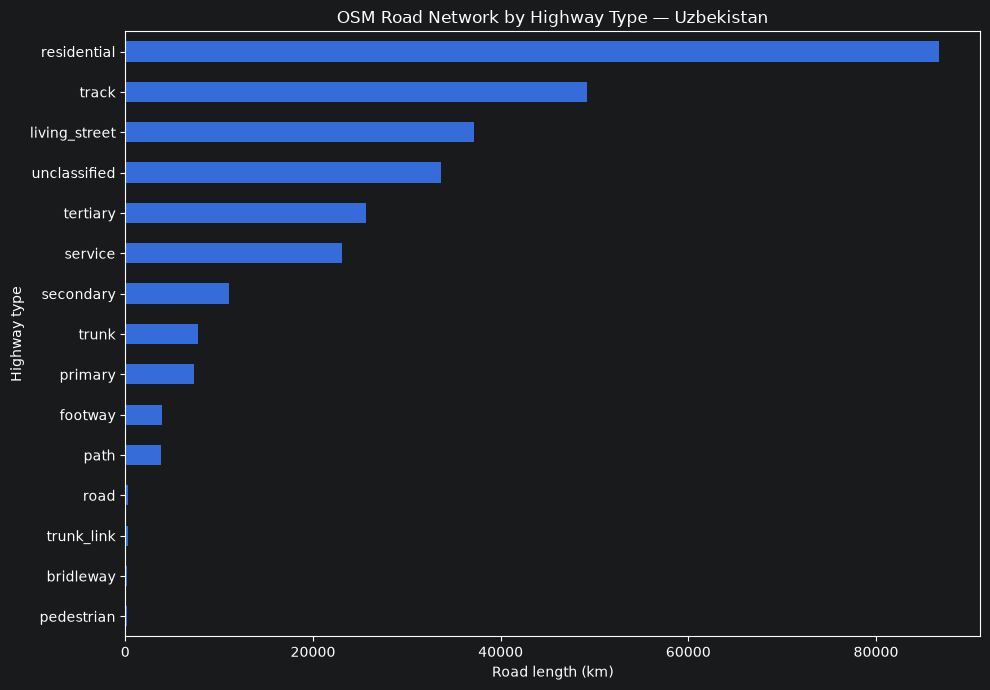

In [8]:
top = highway_length.head(15)

ax = top.plot.barh(
    x="highway",
    y="length_km",
    figsize=(10, 7),
    legend=False,
)

ax.invert_yaxis()
ax.set_xlabel("Road length (km)")
ax.set_ylabel("Highway type")
ax.set_title("OSM Road Network by Highway Type — Uzbekistan")

plt.tight_layout()
plt.show()

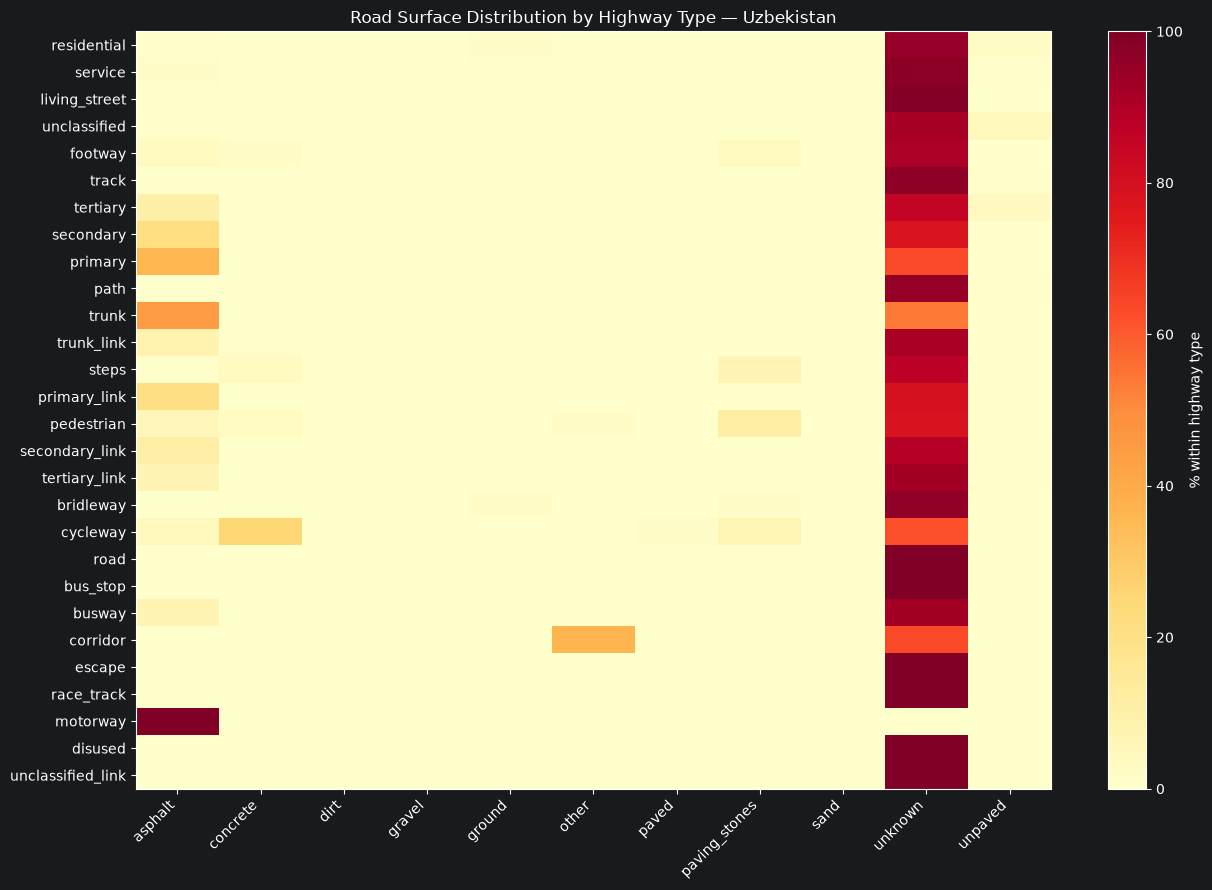

In [9]:
roads_eda = roads.copy()

roads_eda["surface_group"] = (
    roads_eda["surface"].fillna("unknown")
)

# Оставляем 10 наиболее распространённых покрытий,
# остальные объединяем в "other"
top_surfaces = (
    roads_eda["surface_group"]
    .value_counts()
    .head(10)
    .index
)

roads_eda["surface_group"] = (
    roads_eda["surface_group"]
    .where(
        roads_eda["surface_group"].isin(top_surfaces),
        "other"
    )
)

matrix = pd.crosstab(
    roads_eda["highway"],
    roads_eda["surface_group"]
)

# Сортировка по общему количеству сегментов
matrix = matrix.loc[
    matrix.sum(axis=1).sort_values(ascending=False).index
]

# Нормализация внутри каждого типа дороги
matrix_pct = matrix.div(
    matrix.sum(axis=1), axis=0
) * 100

fig, ax = plt.subplots(figsize=(13, 9))

im = ax.imshow(
    matrix_pct,
    cmap="YlOrRd",
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(matrix_pct.columns)))
ax.set_xticklabels(matrix_pct.columns, rotation=45, ha="right")

ax.set_yticks(range(len(matrix_pct.index)))
ax.set_yticklabels(matrix_pct.index)

ax.set_title(
    "Road Surface Distribution by Highway Type — Uzbekistan"
)

fig.colorbar(im, ax=ax, label="% within highway type")

plt.tight_layout()
plt.show()

In [11]:
unknown_stats = (
    roads_eda
    .assign(is_unknown=roads_eda["surface"].isna())
    .groupby("highway")
    .agg(
        total_segments=("is_unknown", "size"),
        unknown_segments=("is_unknown", "sum")
    )
)

unknown_stats["unknown_pct"] = (
    unknown_stats["unknown_segments"]
    / unknown_stats["total_segments"] * 100
)

unknown_stats["share_of_all_unknown_pct"] = (
    unknown_stats["unknown_segments"]
    / unknown_stats["unknown_segments"].sum() * 100
)

display(
    unknown_stats.sort_values(
        "unknown_segments", ascending=False
    )
)

,total_segments,unknown_segments,unknown_pct,share_of_all_unknown_pct
highway,,,,
residential,209216,199295,95.258011,34.115341
living_street,121313,119820,98.769299,20.510801
service,122790,119171,97.052692,20.399706
track,35660,34486,96.707796,5.903317
unclassified,36918,34021,92.152879,5.823719
footway,36283,32774,90.328804,5.610257
tertiary,17514,14921,85.194701,2.554179
secondary,9739,7558,77.605504,1.293779
path,6979,6657,95.386158,1.139546


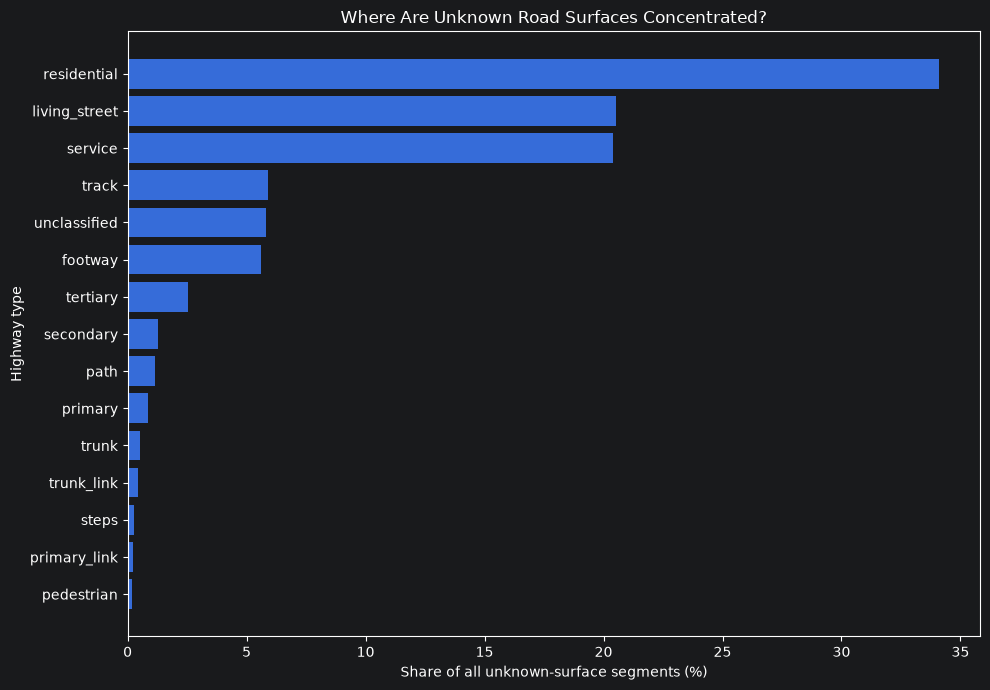

In [12]:
plot_data = (
    unknown_stats
    .sort_values("unknown_segments", ascending=False)
    .head(15)
    .sort_values("unknown_segments")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data.index,
    plot_data["share_of_all_unknown_pct"]
)

ax.set_xlabel("Share of all unknown-surface segments (%)")
ax.set_ylabel("Highway type")
ax.set_title("Where Are Unknown Road Surfaces Concentrated?")

plt.tight_layout()
plt.show()

In [13]:
drivable_types = [
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link",
    "tertiary", "tertiary_link",
    "unclassified", "unclassified_link",
    "residential", "living_street",
    "service", "track",
]

roads_auto = roads[
    roads["highway"].isin(drivable_types)
].copy()

geod = Geod(ellps="WGS84")

roads_wgs84 = roads_auto.to_crs(4326)

roads_auto["length_km"] = (
    roads_wgs84.geometry
    .apply(lambda geom: geod.geometry_length(geom) / 1000)
    .to_numpy()
)

roads_auto["surface_known"] = roads_auto["surface"].notna()

stats = (
    roads_auto
    .groupby("highway")
    .apply(
        lambda g: pd.Series({
            "total_km": g["length_km"].sum(),
            "known_km": g.loc[g["surface_known"], "length_km"].sum(),
        }),
        include_groups=False,
    )
)

stats["known_pct"] = (
    stats["known_km"] / stats["total_km"] * 100
)

stats = stats.sort_values("total_km", ascending=False)

display(stats.round(2))

,total_km,known_km,known_pct
highway,,,
residential,86610.36,6116.91,7.06
track,49080.05,4761.05,9.70
living_street,37134.35,472.47,1.27
unclassified,33615.57,6550.44,19.49
tertiary,25649.43,4437.07,17.30
service,23116.83,1363.60,5.90
secondary,10988.36,2569.79,23.39
trunk,7740.96,4261.80,55.06
primary,7268.33,2237.43,30.78


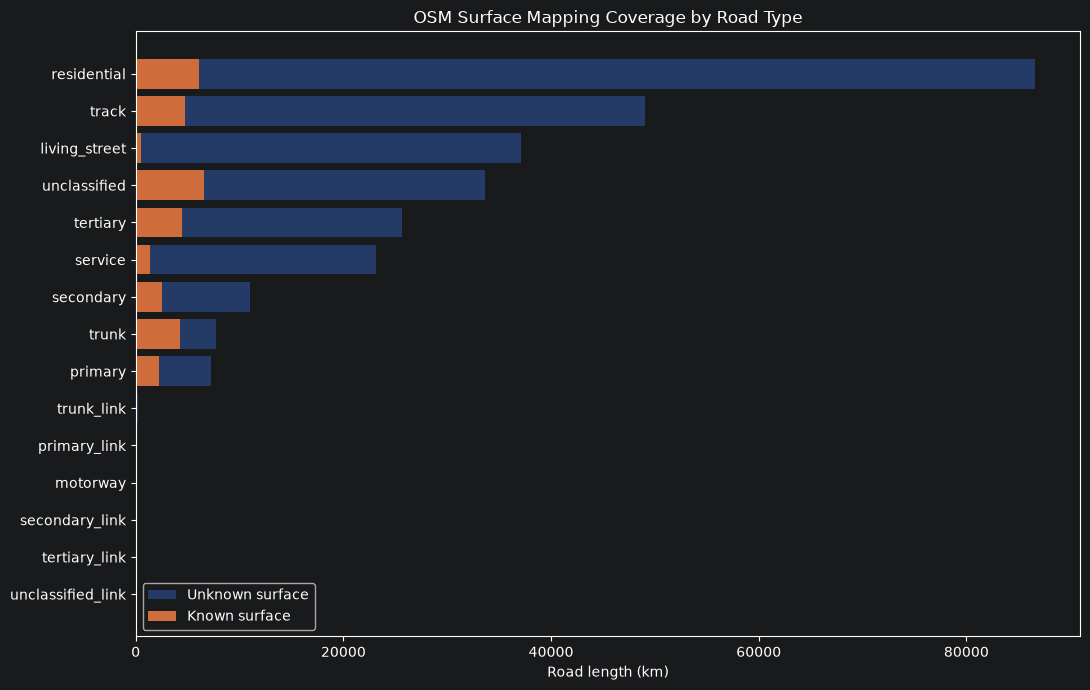

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = stats.sort_values("total_km")

ax.barh(
    plot_data.index,
    plot_data["total_km"],
    label="Unknown surface",
    alpha=0.4,
)

ax.barh(
    plot_data.index,
    plot_data["known_km"],
    label="Known surface",
)

ax.set_xlabel("Road length (km)")
ax.set_title("OSM Surface Mapping Coverage by Road Type")
ax.legend()

plt.tight_layout()
plt.show()